## 1. World Cup 2026 Player Performance Analysis (Data Analyst Project)<br>

A beginner-friendly data analysis project for B.Tech / BCA 1st Year – Data Analyst learners. It analyses what drives goal contributions (goals + assists) of players in a World Cup tournament using Python, pandas, matplotlib and seaborn.<br>

The dataset is synthetic (computer-generated). It contains no real player names or real statistics.<br>

<b>Business problem</b><br>

A national team's coaching staff and scouting analysts want to know which factors go with goals plus assists in a tournament, so they can decide who to start, how to use substitutes, and which players to scout next.<br>

<b>Questions answered:</b><br>

1.What does Goal_Contributions look like overall?<br>
2.Do Minutes_Played and Shots_On_Target affect Goal_Contributions?<br>
3.Does Goal_Contributions differ by Position, Confederation, Preferred_Foot and Squad_Role?<br>
4.Which players need attention? A "Quiet Tournament" player has Goal_Contributions = 0, and players with 400 or more minutes get special attention.

In [92]:
import pandas as pd
df = pd.read_csv("../DATA/RAW data/wc2026_data.csv")
print('Rows, Columns:', df.shape)
df.head(9)

Rows, Columns: (255, 12)


,Player_ID,Position,Confederation,Preferred_Foot,Squad_Role,Age,Minutes_Played,Shots_On_Target,Pass_Accuracy_Pct,Market_Value_Million_EUR,Last_Match_Date,Goal_Contributions
0,P1156,Defender,CAF,Left,Rotation,23.0,250.0,0,75.5,71.1,2026-06-21,2
1,P1037,Midfielder,CONMEBOL,Both,Starter,20.0,660.0,1,86.4,15.1,2026-06-20,3
2,P1245,Midfielder,CONCACAF,Right,Rotation,28.0,200.0,2,82.3,29.8,2026-07-15,2
3,P1089,Forward,CAF,Right,Starter,27.0,620.0,3,80.8,29.4,2026-06-11,2
4,P1030,Defender,CONMEBOL,Right,Starter,32.0,310.0,1,83.3,28.9,2026-07-12,1
5,P1143,Forward,UEFA,Right,Rotation,29.0,300.0,2,83.9,180.0,2026-07-05,0
6,P1244,Goalkeeper,UEFA,Right,Starter,34.0,660.0,0,72.0,27.7,2026-06-22,2
7,P1248,Midfielder,CONMEBOL,Left,Starter,28.0,720.0,7,79.3,NaN,2026-06-12,3
8,P1077,Defender,AFC,Right,Rotation,27.0,180.0,0,77.6,15.7,2026-07-18,2


In [93]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Player_ID                 255 non-null    str    
 1   Position                  255 non-null    str    
 2   Confederation             255 non-null    str    
 3   Preferred_Foot            250 non-null    str    
 4   Squad_Role                255 non-null    str    
 5   Age                       250 non-null    float64
 6   Minutes_Played            251 non-null    float64
 7   Shots_On_Target           255 non-null    int64  
 8   Pass_Accuracy_Pct         255 non-null    float64
 9   Market_Value_Million_EUR  249 non-null    float64
 10  Last_Match_Date           255 non-null    str    
 11  Goal_Contributions        255 non-null    int64  
dtypes: float64(4), int64(2), str(6)
memory usage: 24.0 KB


In [94]:
print('Missing values per column:'); print(df.isna().sum()[df.isna().sum()>0])
print('\nDuplicate rows:', df.duplicated().sum())
df.describe().round(2)

Missing values per column:
Preferred_Foot              5
Age                         5
Minutes_Played              4
Market_Value_Million_EUR    6
dtype: int64

Duplicate rows: 5


,Age,Minutes_Played,Shots_On_Target,Pass_Accuracy_Pct,Market_Value_Million_EUR,Goal_Contributions
count,250.00,251.00,255.00,255.00,249.00,255.00
mean,27.88,373.78,1.17,82.40,46.13,1.65
std,3.86,188.93,1.63,7.17,41.91,1.38
min,18.00,20.00,0.00,60.00,2.90,0.00
25%,26.00,220.00,0.00,77.90,18.00,0.50
50%,28.00,360.00,1.00,82.60,30.50,2.00
75%,30.00,530.00,2.00,86.20,59.20,2.50
max,39.00,720.00,10.00,127.00,180.00,6.00


In [95]:
clean = df.copy()
clean = clean.drop_duplicates()
num_cols = ['Age','Minutes_Played','Market_Value_Million_EUR']
for c in num_cols:
    clean[c] = clean[c].fillna(clean[c].median())
    clean["Preferred_Foot"] = clean["Preferred_Foot"].fillna(clean['Preferred_Foot'].mode()[0])
print('Rows after cleaning:', len(clean), '| Missing values left:', clean.isna().sum().sum())

Rows after cleaning: 250 | Missing values left: 0


In [96]:
clean['Contributions_Per_90'] = (clean['Goal_Contributions'] / clean['Minutes_Played'] * 90).round(2)
def grade(m):
    if m>=0.75: return 'Star'
    if m>=0.4: return 'Contributor'
    if m>=0.1: return 'Occasional'
    return 'Quiet'
clean['Impact_Band'] = clean['Contributions_Per_90'].apply(grade)
clean['Passing_Band'] = pd.cut(clean['Pass_Accuracy_Pct'],[0,70,80,90,100],labels=['<70%','70-80%','80-90%','>90%'])
clean[['Player_ID','Contributions_Per_90','Impact_Band','Passing_Band']].head()

,Player_ID,Contributions_Per_90,Impact_Band,Passing_Band
0,P1156,0.72,Contributor,70-80%
1,P1037,0.41,Contributor,80-90%
2,P1245,0.90,Star,80-90%
3,P1089,0.29,Occasional,80-90%
4,P1030,0.29,Occasional,80-90%


In [97]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


count    250.0
mean       0.5
std        0.8
min        0.0
25%        0.0
50%        0.4
75%        0.6
max        9.0
Name: Contributions_Per_90, dtype: float64


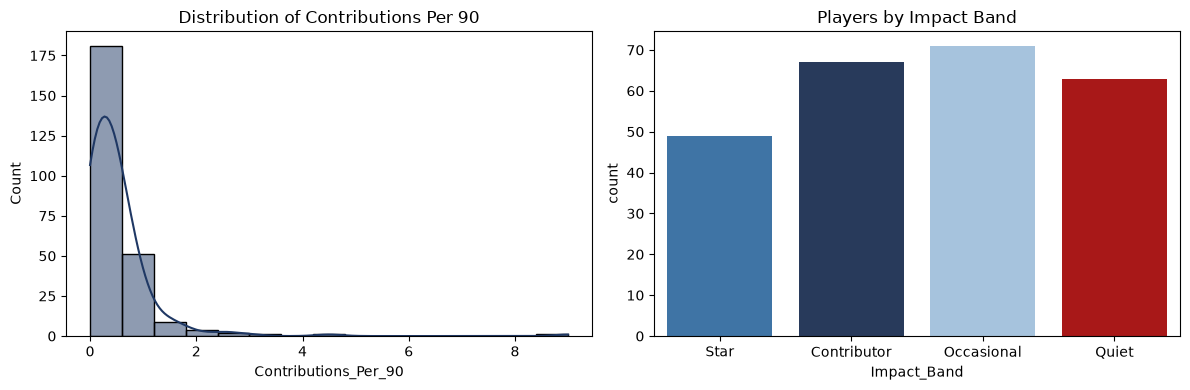

In [98]:
import matplotlib.pyplot as plt
import seaborn as sns
print(clean['Contributions_Per_90'].describe().round(1))
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.histplot(clean['Contributions_Per_90'],bins=15,kde=True,color='#1F3864',ax=ax[0]);ax[0].set_title('Distribution of Contributions Per 90')
order=['Star','Contributor','Occasional','Quiet']
sns.countplot(data=clean,x='Impact_Band',hue='Impact_Band',legend=False,order=order,palette=['#1F3864','#2E75B6','#9DC3E6','#C00000'],ax=ax[1]);ax[1].set_title('Players by Impact Band')
plt.tight_layout();plt.savefig('../images/01_overall_performance.png');plt.show()

In [99]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Q1.What does Goal_Contributions look like overall?

count    250.0
mean       1.6
std        1.4
min        0.0
25%        0.2
50%        1.5
75%        2.0
max        6.0
Name: Goal_Contributions, dtype: float64


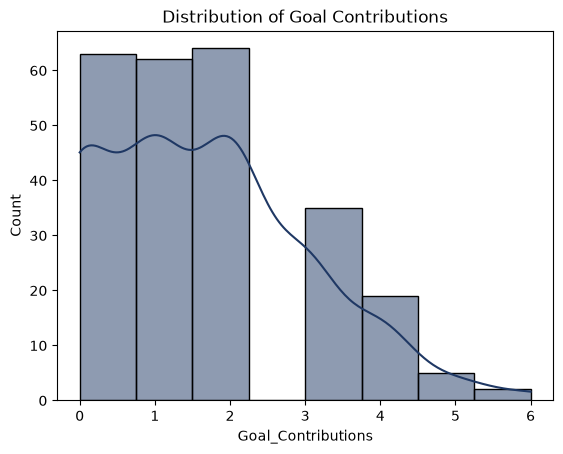

In [100]:
print(clean['Goal_Contributions'].describe().round(1))
sns.histplot(clean['Goal_Contributions'],bins=8,kde=True,color='#1F3864')
plt.title('Distribution of Goal Contributions')
plt.savefig('../images/Q.01_goal_contributions_distribution.png')
plt.show()

## Q2.Do Minutes_Played and Shots_On_Target affect Goal_Contributions?

In [101]:
clean['Minutes_Band']=pd.cut(clean['Minutes_Played'],[0,200,400,600,720],labels=['<200','200-400','400-600','>600'])
clean['Shots_Band']=pd.cut(clean['Shots_On_Target'],[-1,0,2,5,50],labels=['0','1-2','3-5','6+'])

print("Average contributions by minutes band")
for band in ['<200','200-400','400-600','>600']:
    print(band, round(clean[clean['Minutes_Band']==band]['Goal_Contributions'].mean(),2))

print("Average contributions by shots-on-target band")
for band in ['0','1-2','3-5','6+']:
    print(band, round(clean[clean['Shots_Band']==band]['Goal_Contributions'].mean(),2))
  

Average contributions by minutes band
<200 0.98
200-400 1.36
400-600 2.11
>600 2.29
Average contributions by shots-on-target band
0 1.12
1-2 1.62
3-5 2.93
6+ 4.25


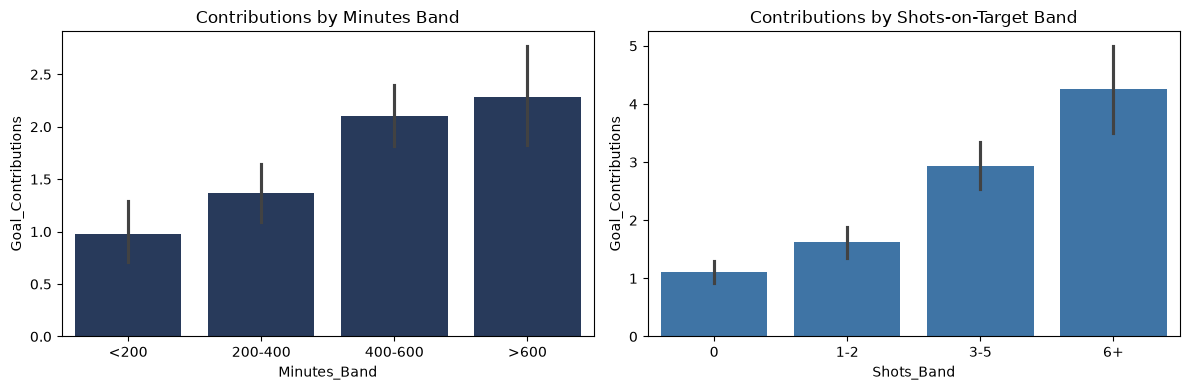

In [102]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.barplot(data=clean,x='Minutes_Band',y='Goal_Contributions',color='#1F3864',ax=ax[0]);ax[0].set_title('Contributions by Minutes Band')
sns.barplot(data=clean,x='Shots_Band',y='Goal_Contributions',color='#2E75B6',ax=ax[1]);ax[1].set_title('Contributions by Shots-on-Target Band')
plt.tight_layout();plt.savefig('../images/Q.02_minutes_shots_vs_contributions.png');plt.show()

## Q3.Does Goal_Contributions differ by Position, Confederation, Preferred_Foot and Squad_Role?

In [103]:
groups={'Position':['Forward','Midfielder','Defender','Goalkeeper'],
        'Confederation':['UEFA','CONMEBOL','CAF','AFC','CONCACAF'],
        'Preferred_Foot':['Right','Left','Both'],
        'Squad_Role':['Starter','Rotation','Substitute']}

for col in groups:
    print(col)
    for g in groups[col]:
        print("  ",g, round(clean[clean[col]==g]['Goal_Contributions'].mean(),2))
        

Position
   Forward 2.25
   Midfielder 1.57
   Defender 1.26
   Goalkeeper 1.43
Confederation
   UEFA 1.55
   CONMEBOL 1.52
   CAF 1.95
   AFC 1.57
   CONCACAF 1.68
Preferred_Foot
   Right 1.61
   Left 1.73
   Both 1.5
Squad_Role
   Starter 2.07
   Rotation 1.34
   Substitute 0.76


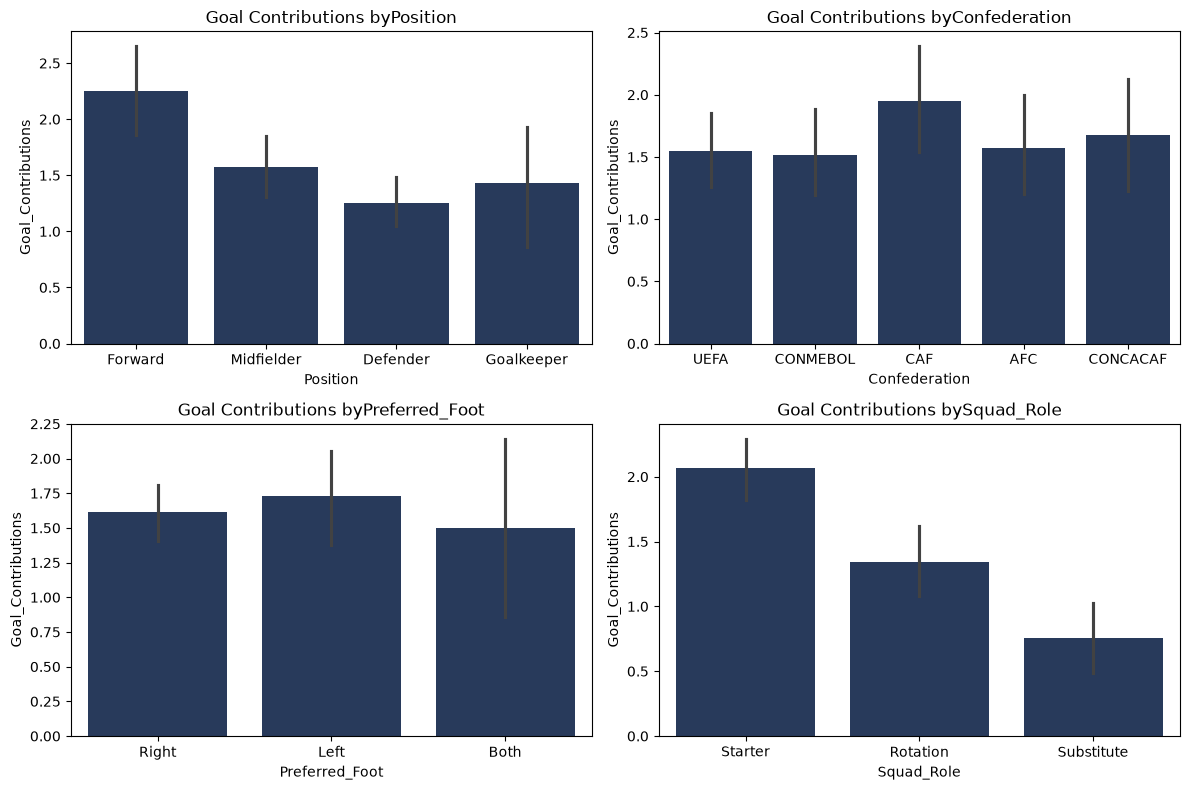

In [104]:
fig,ax=plt.subplots(2,2,figsize=(12,8))
for a,col in zip(ax.flatten(),groups):
    sns.barplot(data=clean,x=col,y='Goal_Contributions',order=groups[col],color='#1F3864',ax=a);a.set_title('Goal Contributions by'+col)
plt.tight_layout();plt.savefig('../images/Q.03_group_comparison.png');plt.show()    


## Q4.Which players need attention? A "Quiet Tournament" player has Goal_Contributions = 0, and players with 400 or more minutes get special attention.

Quiet players: 63 | Others: 187
Average minutes - Quiet: 274.1 | Others: 405.8


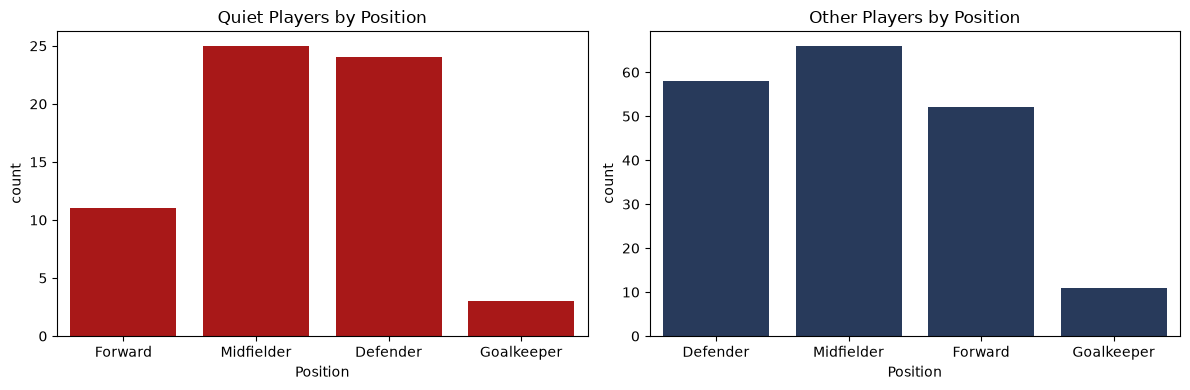

Quiet players with 400+ minutes: 12
    Player_ID    Position  Minutes_Played  Shots_On_Target  Goal_Contributions
16      P1114  Midfielder           490.0                2                   0
35      P1141    Defender           720.0                0                   0
41      P1130    Defender           630.0                2                   0
61      P1012    Defender           550.0                1                   0
95      P1019  Midfielder           660.0                1                   0
109     P1152  Midfielder           570.0                0                   0
130     P1210    Defender           620.0                0                   0
136     P1242  Midfielder           470.0                0                   0
181     P1162    Defender           410.0                0                   0
193     P1045  Midfielder           400.0                1                   0


In [105]:
quiet=clean[clean['Goal_Contributions']==0]
rest=clean[clean['Goal_Contributions']>0]
print("Quiet players:",len(quiet),"| Others:",len(rest))
print("Average minutes - Quiet:",round(quiet['Minutes_Played'].mean(),1),"| Others:",round(rest['Minutes_Played'].mean(),1))

fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.countplot(data=quiet,x='Position',color='#C00000',ax=ax[0]);ax[0].set_title('Quiet Players by Position')
sns.countplot(data=rest,x='Position',color='#1F3864',ax=ax[1]);ax[1].set_title('Other Players by Position')
plt.tight_layout();plt.savefig('../images/Q.04_quiet_players_by_position.png');plt.show()

attention=quiet[quiet['Minutes_Played']>=400]
print("Quiet players with 400+ minutes:",len(attention))
print(attention[['Player_ID','Position','Minutes_Played','Shots_On_Target','Goal_Contributions']].head(10))

## 2.KEY INSIGHTS:(generated from data)

In [106]:
r_min=clean['Minutes_Played'].corr(clean['Goal_Contributions']);r_sot=clean['Shots_On_Target'].corr(clean['Goal_Contributions'])
best=clean.groupby('Position')['Goal_Contributions'].mean().idxmax();worst=clean.groupby('Position')['Goal_Contributions'].mean().idxmin()
role=clean.groupby('Squad_Role')['Goal_Contributions'].mean()
print(f"1. Average goal contributions: {clean['Goal_Contributions'].mean():.1f}; median {clean['Goal_Contributions'].median():.1f}.")
print(f"2. Minutes played vs contributions correlation = {r_min:.2f}; shots on target vs contributions = {r_sot:.2f} (both positive).")
print(f"3. Highest-contributing position: {best}; lowest: {worst}.")
print(f"4. Starters average {role['Starter']:.1f} vs {role['Substitute']:.1f} for substitutes.")
print(f"5. {len(quiet)} players had a Quiet Tournament; their average minutes played is {quiet['Minutes_Played'].mean():.0f}.")

1. Average goal contributions: 1.6; median 1.5.
2. Minutes played vs contributions correlation = 0.39; shots on target vs contributions = 0.53 (both positive).
3. Highest-contributing position: Forward; lowest: Defender.
4. Starters average 2.1 vs 0.8 for substitutes.
5. 63 players had a Quiet Tournament; their average minutes played is 274.


 ## 3.Save the Cleaned Data

In [107]:
clean.to_csv('../data/processed/player_clean.csv',index=False)
print('Saved cleaned file with', len(clean), 'rows')

Saved cleaned file with 250 rows


## 4. Recommendations

- Coaches should **track minutes and shots on target** during the tournament, because players with more of both tend to have more goal contributions.
- **Give starters and forwards attacking support**, since they contribute the most on average, and use **substitutes in matches** where extra attacking impact is needed.
- Review players flagged as **Quiet Tournament** (0 contributions), especially those with **400 or more minutes**, to check their role, position and form.

> **Remember:** correlation does not prove causation. This analysis shows association, not cause.

In [108]:
with open("requirements.txt","w",encoding="utf-8") as f:
    f.write("Pandas\n")
    f.write("Numpy\n")
    f.write("matplotlib\n")
    f.write("seaborn\n")
    f.write("jupyter\n")
    f.write("git\n")
    f.write("github\n")
    print("File written. Is it closed?",f.closed)  
with open("requirements.txt","r",encoding="utf-8") as f:
    content = f.read()
    print(content)  

File written. Is it closed? False
Pandas
Numpy
matplotlib
seaborn
jupyter
git
github

